In [6]:
import os
import sys
import glob
 
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
sys.path.append("..")
from config import SAMPLE_DIR, MANIFEST_PATH, CATEGORIES
 
ROOT = os.path.abspath("..")
 
def root_path(*parts):
    return os.path.join(ROOT, *parts)

In [8]:
manifest_path = root_path(MANIFEST_PATH)
 
if os.path.exists(manifest_path):
    df = pd.read_csv(manifest_path)
    print(f"Loaded manifest from {manifest_path}")
else:
    print(f"No manifest found at {manifest_path} -- scanning idnet_sample/ directly instead.")
    records = []
    sample_dir = root_path(SAMPLE_DIR)
    for label in ["real", "fake"]:
        for category in CATEGORIES.keys():
            for f in glob.glob(os.path.join(sample_dir, label, category, "*.*")):
                records.append({"filepath": f, "label": label, "document_type": category})
    df = pd.DataFrame(records)
 
print(f"{len(df)} image records loaded")
df.head()

No manifest found at c:\Users\mecar\Github\Telecom-2A-classification-and-fraud-detection-for-sensitive-documents\idnet_processed_manifest.csv -- scanning idnet_sample/ directly instead.
0 image records loaded


""


KeyError: 'label'

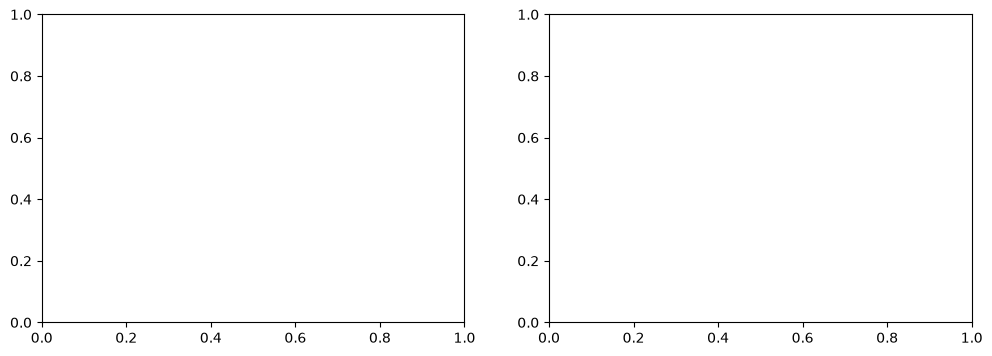

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
 
df["label"].value_counts().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#C44E52"])
axes[0].set_title("Real vs. Fake Document Counts")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Count")
 
sns.countplot(data=df, x="document_type", hue="label", ax=axes[1])
axes[1].set_title("Document Type by Label")
axes[1].tick_params(axis="x", rotation=30)
 
plt.tight_layout()
plt.show()
 
summary = df.groupby(["document_type", "label"]).size().reset_index(name="count")
summary

In [13]:
from config import ARCHIVE_PATH
import shutil

archive_full_path = root_path(ARCHIVE_PATH)
print("Looking for archive at:", archive_full_path)
print("Exists?", os.path.exists(archive_full_path))

# Clean up the partial/failed Kaggle download so we start fresh
shutil.rmtree(root_path("idnet_raw"), ignore_errors=True)
print("Cleared idnet_raw/")

Looking for archive at: c:\Users\mecar\Github\Telecom-2A-classification-and-fraud-detection-for-sensitive-documents\data\files-archive.file
Exists? False
Cleared idnet_raw/


In [1]:
import shutil
shutil.rmtree(root_path("idnet_raw"), ignore_errors=True)
print("Cleared idnet_raw/")

NameError: name 'root_path' is not defined